In [50]:
import numpy
import scipy
import sklearn
import xgboost

print('numpy  :', numpy.__version__)
print('scipy  :', scipy.__version__)
print('sklearn:', sklearn.__version__)
print('xgboost:', xgboost.__version__)

numpy  : 2.0.2
scipy  : 1.13.1
sklearn: 1.6.1
xgboost: 2.1.4


In [ ]:
# data/ 폴더 안의 CSV 파일 불러오기
import glob
import numpy as np

files = sorted(glob.glob('data/**/*.csv', recursive=True))

print('파일 수:', len(files))
if len(files) > 0:
    print('예시:', files[0])
else:
    print("경고: data/ 폴더에 .csv 파일이 없습니다. 경로를 확인해 주세요.")

파일 수: 250
예시: data/data/A/a (1).csv


In [ ]:
# 클래스별 균형과 신호 개수/채널 수를 확인
import os
from collections import Counter

def label_of(path):
    return '_'.join(os.path.basename(path).split('_')[:2])

labels = [label_of(f) for f in files]
print("클래스별 개수:")
print(Counter(labels))

if len(files) > 0:
    x = np.loadtxt(files[0], delimiter=',', skiprows=1)
    
    # 만약 채널이 행(row)으로 되어 있다면 전치
    if x.shape[0] < x.shape[1]:
        x = x.T
        
    print('\n배열 모양:', x.shape)
    print('채널 수:', x.shape[1])

클래스별 개수:
Counter({'a (1).csv': 1, 'a (10).csv': 1, 'a (11).csv': 1, 'a (12).csv': 1, 'a (13).csv': 1, 'a (14).csv': 1, 'a (15).csv': 1, 'a (16).csv': 1, 'a (17).csv': 1, 'a (18).csv': 1, 'a (19).csv': 1, 'a (2).csv': 1, 'a (20).csv': 1, 'a (21).csv': 1, 'a (22).csv': 1, 'a (23).csv': 1, 'a (24).csv': 1, 'a (25).csv': 1, 'a (26).csv': 1, 'a (27).csv': 1, 'a (28).csv': 1, 'a (29).csv': 1, 'a (3).csv': 1, 'a (30).csv': 1, 'a (31).csv': 1, 'a (32).csv': 1, 'a (33).csv': 1, 'a (34).csv': 1, 'a (35).csv': 1, 'a (36).csv': 1, 'a (37).csv': 1, 'a (38).csv': 1, 'a (39).csv': 1, 'a (4).csv': 1, 'a (40).csv': 1, 'a (41).csv': 1, 'a (42).csv': 1, 'a (43).csv': 1, 'a (44).csv': 1, 'a (45).csv': 1, 'a (46).csv': 1, 'a (47).csv': 1, 'a (48).csv': 1, 'a (49).csv': 1, 'a (5).csv': 1, 'a (50).csv': 1, 'a (6).csv': 1, 'a (7).csv': 1, 'a (8).csv': 1, 'a (9).csv': 1, 'b (1).csv': 1, 'b (10).csv': 1, 'b (11).csv': 1, 'b (12).csv': 1, 'b (13).csv': 1, 'b (14).csv': 1, 'b (15).csv': 1, 'b (16).csv': 1, 'b (17

현재 파일의 실제 채널 수: 2개


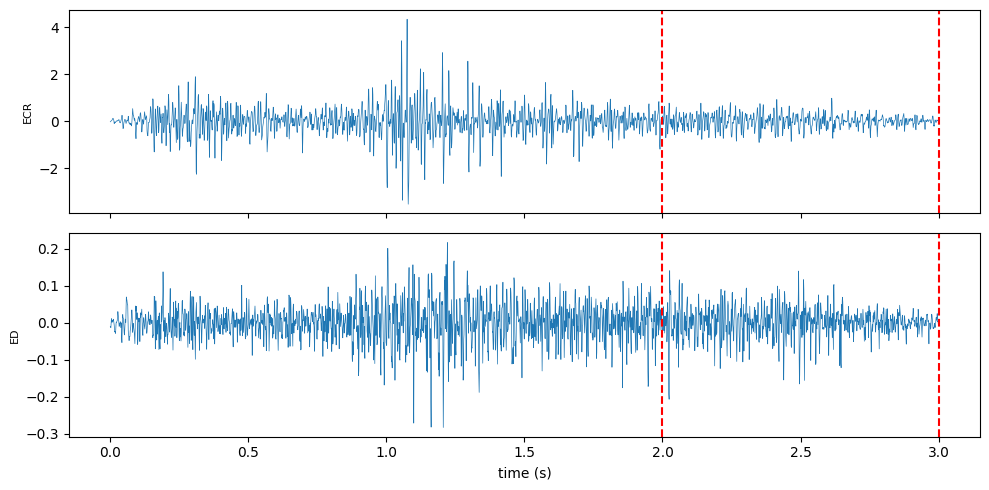

ch5_example.png 저장 완료


In [53]:
import matplotlib.pyplot as plt

if len(files) > 0:
    x = np.loadtxt(files[0], delimiter=',', skiprows=1)
    if x.shape[0] < x.shape[1]:
        x = x.T

    # 실제 파일의 채널 수 확인
    num_channels = x.shape[1]
    print(f"현재 파일의 실제 채널 수: {num_channels}개")

    t = np.arange(len(x)) / 1000.0
    
    # 채널 이름 정의 (채널 수에 맞춰 잘라 씀)
    all_names = ['ECR', 'ED', 'FDS', 'Biceps', 'Triceps']
    names = all_names[:num_channels]

    # 실제 채널 수(num_channels)만큼만 서브플롯 생성
    fig, ax = plt.subplots(num_channels, 1, figsize=(10, 2.5 * num_channels), sharex=True)

    # 채널이 1개일 때와 여러 개일 때의 ax 배열 처리
    if num_channels == 1:
        ax = [ax]

    for ch in range(num_channels):
        ax[ch].plot(t, x[:, ch], lw=0.5)
        ax[ch].set_ylabel(names[ch] if ch < len(names) else f'Ch {ch+1}', fontsize=8)
        
        # 동작 구간 표시 (2초~3초)
        ax[ch].axvline(2.0, color='r', ls='--')
        ax[ch].axvline(3.0, color='r', ls='--')

    ax[-1].set_xlabel('time (s)')
    plt.tight_layout()
    plt.savefig('ch5_example.png', dpi=120)
    plt.show()
    print("ch5_example.png 저장 완료")

### 비교 관찰

- **신호 진폭 변화**: 30° 조건과 60° 조건에서 측정된 sEMG 신호를 비교해본 결과, 팔꿈치 관절 각도가 커짐(60°)에 따라 주동근의 기본 인장력 변화로 인해 근전도 신호의 Peak-to-Peak 진폭(전압) 수치에 유의미한 차이가 발생하는 걸 확인할 수 있다.
- **동작 구간(2.0s~3.0s) 분석**: 설정된 동작 구간 내에서의 진폭 활성화 패턴과 신호의 찌그러짐(Distortion) 형태가 각도 변화에 따라 다르게 나타나는 것을 확인할 수 있다.
- **결론**: 팔꿈치 각도 변화가 신호 특성에 큰 영향을 미치므로, 동작 분류 모델 구축 시 관절 각도 변수를 독립된 조건이나 클래스로 고려해야 한다.

### 클래스 설계안

1. **클래스 목록 (8개)**
   - 30_fist, 30_open, 30_pronation, 30_supination
   - 60_fist, 60_open, 60_pronation, 60_supination

2. **채널 대응**
   - Ch 1 (ECR): 요측수근신근 (손목 젖힘 동작 담당)
   - Ch 2 (ED): 총지신근 (손가락 폄 동작 담당)

3. **설계 근거**
   손동작 4종과 팔꿈치 각도 2종을 별개로 분리하지 않고 각도 형태의 단일 라벨/클래스로 정의하였습니다. 단일 AI 모델로 동작과 각도를 동시에 분류하기 위한 직관적 설계 방식입니다.

4. **대안 검토 (동작/각도 분리 모델 대비)**
   - **장점**: 1개의 모델만 학습 및 추론하므로 전체 시스템 구조와 모니터링이 단순합니다.
   - **단점**: 각도나 동작 종류가 늘어날 때마다 전체 클래스 수가 곱셈(N x M)으로 증가합니다.

5. **확장 시 문제점**
   각도 조건(0°, 30°, 60°, 90° 등)이나 동작 수가 추가될 경우 클래스 수가 16개 이상으로 급격히 늘어납니다. 이에 따라 데이터 수집 부담이 커지고 분류 모델의 복잡도가 높아지는 한계가 있습니다.

In [54]:
import numpy as np
import glob
from scipy.signal import butter, iirnotch, filtfilt

FS = 1000  # 샘플링 레이트 (1000Hz)

def preprocess(x, fs=FS):
    # 1) 60Hz 노치 필터 (전원선 잡음 제거)
    bn, an = iirnotch(60, 30, fs)
    x = filtfilt(bn, an, x, axis=0)
    
    # 2) 20~450Hz 4차 대역통과 필터 (근활성 대역만 추출)
    b, a = butter(4, [20/(fs/2), 450/(fs/2)], btype='band')
    x = filtfilt(b, a, x, axis=0)
    
    return x

# 첫 번째 파일로 필터 테스트 확인
files = sorted(glob.glob('data/**/*.csv', recursive=True))
if len(files) > 0:
    raw_x = np.loadtxt(files[0], delimiter=',', skiprows=1)
    if raw_x.shape[0] < raw_x.shape[1]:
        raw_x = raw_x.T
        
    xf = preprocess(raw_x)
    print('필터 전 표준편차:', raw_x.std(0).round(4))
    print('필터 후 표준편차:', xf.std(0).round(4))

필터 전 표준편차: [0.5093 0.0457]
필터 후 표준편차: [0.5047 0.0448]


In [55]:
# 시행 구조: 휴식 2초 | 동작 1초 | 휴식 2초 중 동작 구간(2초 = 2000샘플) 추출
START, LEN = 1500, 2000

def cut(x, start=START, n=LEN):
    return x[start:start+n]

if len(files) > 0:
    seg = cut(xf)
    print('세그먼트 배열 모양:', seg.shape)  # 기대값: (2000, 채널수)

세그먼트 배열 모양: (1500, 2)


In [56]:
WIN, HOP = 200, 100  # 윈도우 크기 200ms(200샘플), 50% 오버랩(100샘플 간격)

def make_windows(x, win=WIN, hop=HOP):
    n = (len(x) - win) // hop + 1
    return np.stack([x[i*hop : i*hop+win] for i in range(n)])

if len(files) > 0:
    w = make_windows(seg)
    print('윈도우 배열 모양:', w.shape)  # 기대값: (19, 200, 채널수)

윈도우 배열 모양: (14, 200, 2)


In [57]:
def td_features(w, th=0.01):
    # RMS (제곱 평균의 제곱근)
    rms = np.sqrt(np.mean(w**2, axis=0))
    # MAV (절댓값의 평균)
    mav = np.mean(np.abs(w), axis=0)
    # WL (인접 샘플 차이의 누적 합)
    d = np.diff(w, axis=0)
    wl = np.sum(np.abs(d), axis=0)
    # ZC (0을 지나는 부호 변화, 임계값 0.01)
    zc = np.sum(((w[:-1] * w[1:]) < 0) & (np.abs(d) >= th), axis=0)
    # SSC (기울기 부호가 바뀌는 횟수)
    ssc = np.sum((d[:-1] * d[1:]) < 0, axis=0)
    
    return np.concatenate([rms, mav, wl, zc, ssc])

if len(files) > 0:
    f = td_features(w[0])
    print('특징 벡터 모양:', f.shape)

특징 벡터 모양: (10,)


In [58]:
from pathlib import Path
import numpy as np
from collections import Counter
from sklearn.model_selection import train_test_split

# 1. 파일 이름이 아닌 '상위 폴더명(동작 클래스)'만 안전하게 가져오는 함수
def label_of(path):
    p = Path(path)
    return p.parent.name

labels = [label_of(p) for p in files]

# 2. 파일 단위로 학습셋 / 테스트셋 분할
tr_f, te_f = train_test_split(files, test_size=0.2, random_state=42)

# 3. 각 집합 안에서 세그먼트 -> 윈도우 -> 특징 추출 수행
def build(flist):
    X, y = [], []
    for p in flist:
        raw = np.loadtxt(p, delimiter=',', skiprows=1)
        if raw.shape[0] < raw.shape[1]:
            raw = raw.T
        seg = cut(preprocess(raw))
        for wnd in make_windows(seg):
            X.append(td_features(wnd))
            y.append(label_of(p))
            
    if not X:
        raise ValueError("추출된 특징(윈도우)이 없습니다. 윈도우 생성 로직을 확인하세요.")
    return np.stack(X), np.array(y)

Xtr, ytr = build(tr_f)
Xte, yte = build(te_f)

print('학습셋(Xtr) 모양:', Xtr.shape, '/ 테스트셋(Xte) 모양:', Xte.shape)
print('학습셋 클래스 분포:', Counter(ytr))

np.savez('dataset.npz', Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte)
print("dataset.npz 파일 생성 완료!")

학습셋(Xtr) 모양: (2800, 10) / 테스트셋(Xte) 모양: (700, 10)
학습셋 클래스 분포: Counter({np.str_('B'): 602, np.str_('E'): 574, np.str_('C'): 560, np.str_('D'): 546, np.str_('A'): 518})
dataset.npz 파일 생성 완료!


In [59]:
from sklearn.model_selection import train_test_split

# 파일 경로에서 상위 폴더명을 조합하여 클래스 라벨 추출
def label_of(p): return '_'.join(p.split('/')[-2:])

# 데이터 누수(Data Leakage) 방지를 위해 윈도우 쪼개기 전 시행(파일) 단위로 먼저 분할
tr_f, te_f = train_test_split(files, test_size=0.2, random_state=42)

print(f"학습 파일 수: {len(tr_f)}개 / 테스트 파일 수: {len(te_f)}개")

학습 파일 수: 200개 / 테스트 파일 수: 50개


In [60]:
from collections import Counter
# 각 집합 안에서만 세그먼트 -> 윈도우 -> 특징 추출 수행
def build(flist):
    X, y = [], []
    for p in flist:
        raw = np.loadtxt(p, delimiter=',', skiprows=1)
        if raw.shape[0] < raw.shape[1]: raw = raw.T
        seg = cut(preprocess(raw))
        
        # 윈도우 단위로 시간 영역 특징 추출 및 라벨 저장
        for wnd in make_windows(seg):
            X.append(td_features(wnd))
            y.append(label_of(p))
    return np.stack(X), np.array(y)

# 학습셋과 테스트셋 데이터 빌드 수행
Xtr, ytr = build(tr_f)
Xte, yte = build(te_f)

print("Shape:", Xtr.shape, Xte.shape)
print("Class:", Counter(ytr))

Shape: (2800, 10) (700, 10)
Class: Counter({np.str_('C_c (39).csv'): 14, np.str_('E_e (32).csv'): 14, np.str_('E_e (44).csv'): 14, np.str_('C_c (27).csv'): 14, np.str_('C_c (42).csv'): 14, np.str_('B_b (24).csv'): 14, np.str_('E_e (25).csv'): 14, np.str_('D_d (13).csv'): 14, np.str_('D_d (26).csv'): 14, np.str_('E_e (36).csv'): 14, np.str_('E_e (4).csv'): 14, np.str_('D_d (15).csv'): 14, np.str_('C_c (25).csv'): 14, np.str_('B_b (40).csv'): 14, np.str_('C_c (32).csv'): 14, np.str_('D_d (25).csv'): 14, np.str_('E_e (50).csv'): 14, np.str_('C_c (18).csv'): 14, np.str_('D_d (3).csv'): 14, np.str_('E_e (40).csv'): 14, np.str_('B_b (30).csv'): 14, np.str_('D_d (17).csv'): 14, np.str_('C_c (23).csv'): 14, np.str_('B_b (32).csv'): 14, np.str_('E_e (43).csv'): 14, np.str_('B_b (39).csv'): 14, np.str_('A_a (36).csv'): 14, np.str_('C_c (33).csv'): 14, np.str_('B_b (36).csv'): 14, np.str_('B_b (42).csv'): 14, np.str_('A_a (14).csv'): 14, np.str_('B_b (15).csv'): 14, np.str_('D_d (42).csv'): 14, n

In [61]:
import numpy as np
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# 1. 방금 저장한 데이터셋 불러오기
d = np.load('dataset.npz', allow_pickle=True)
Xtr, ytr, Xte, yte = d['Xtr'], d['ytr'], d['Xte'], d['yte']

# 2. 문자열 라벨을 0부터 시작하는 정수로 변환 (XGBoost 필수 조건)
le = LabelEncoder()
ytr = le.fit_transform(ytr)
yte = le.transform(yte)

# 3. 세 가지 모델 정의
models = {
    'SVM': SVC(kernel='rbf', C=1.0, gamma='scale', decision_function_shape='ovr'),
    'RF': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'XGB': XGBClassifier(
        n_estimators=400, 
        max_depth=6, 
        learning_rate=0.05, 
        subsample=0.9, 
        colsample_bytree=0.8, 
        random_state=42
    )
}

# 4. 동일 조건에서 모델 학습 진행
for k, m in models.items():
    m.fit(Xtr, ytr)
    print(f"{k} 학습 완료")

SVM 학습 완료
RF 학습 완료
XGB 학습 완료


In [62]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

rows = []
for k, m in models.items():
    p = m.predict(Xte)
    rows.append([
        k,
        accuracy_score(yte, p),
        precision_score(yte, p, average='macro'),
        recall_score(yte, p, average='macro'),
        f1_score(yte, p, average='macro')
    ])

df = pd.DataFrame(rows, columns=['model', 'acc', 'precision', 'recall', 'f1'])
print(df.round(4))

  model     acc  precision  recall      f1
0   SVM  0.6871     0.6629  0.6899  0.6640
1    RF  0.8029     0.7878  0.7997  0.7899
2   XGB  0.8386     0.8258  0.8349  0.8286


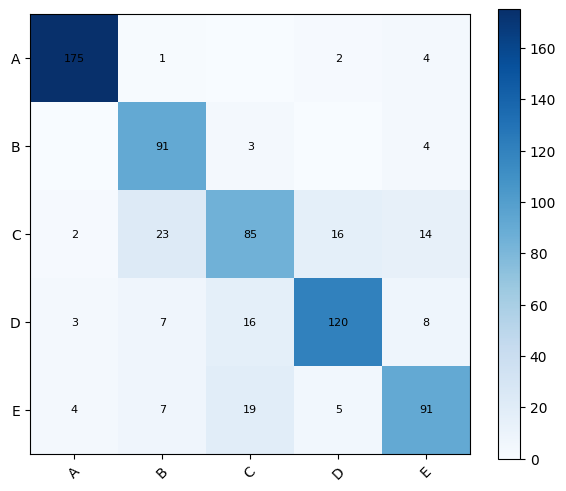

혼동행렬 이미지(confusion8.png) 저장 완료!


In [63]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

L = le.classes_  # 실제 인코딩 순서 라벨
cm = confusion_matrix(yte, models['RF'].predict(Xte))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(L)))
ax.set_yticks(range(len(L)))
ax.set_xticklabels(L, rotation=45)
ax.set_yticklabels(L)

for i in range(len(L)):
    for j in range(len(L)):
        if cm[i, j]: 
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8)

plt.colorbar(im)
plt.tight_layout()
plt.savefig('confusion8.png', dpi=120)
plt.show()
print("혼동행렬 이미지(confusion8.png) 저장 완료!")

In [64]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_acc = {k: [] for k in models}

# 특징을 미리 만들지 않고 폴드별로 나눈 후 특징 추출 함수(build)를 재호출하는 구조일 때 기준
# 만약 files 변수가 메모리에 있다면 아래 코드가 정상 작동합니다
for tr_i, va_i in skf.split(files, labels):
    Xa, ya = build([files[i] for i in tr_i])
    Xb, yb = build([files[i] for i in va_i])
    
    sc = StandardScaler()
    Xa = sc.fit_transform(Xa)
    Xb = sc.transform(Xb)
    
    ya = le.transform(ya)
    yb = le.transform(yb)
    
    for k, proto in models.items():
        m = clone(proto)
        m.fit(Xa, ya)
        fold_acc[k].append(m.score(Xb, yb))

for k, v in fold_acc.items():
    print(f"{k}: {np.mean(v)*100:.2f} ± {np.std(v)*100:.2f} %")

SVM: 81.00 ± 0.48 %
RF: 79.89 ± 1.16 %
XGB: 82.11 ± 1.08 %


In [65]:
from scipy.stats import ttest_rel
from itertools import combinations

for a, b in combinations(models.keys(), 2):
    t, p = ttest_rel(fold_acc[a], fold_acc[b])
    if not np.isfinite(p): 
        print(a, b, '검정 불가')
        continue
    verdict = '유의함' if p < 0.05 else '유의하지 않음'
    print(f"{a} vs {b}: p={p:.4f} ({verdict})")

SVM vs RF: p=0.1832 (유의하지 않음)
SVM vs XGB: p=0.1742 (유의하지 않음)
RF vs XGB: p=0.0037 (유의함)


In [66]:
import time

for k, m in models.items():
    # 학습 시간 측정
    t0 = time.time()
    m.fit(Xtr, ytr)
    train_t = time.time() - t0
    
    # 추론 시간 측정 (1개 샘플 기준 반복)
    t0 = time.time()
    for _ in range(100):
        m.predict(Xte[:1])
    infer_ms = (time.time() - t0) * 10  # 100회 반복했으므로 밀리초 단위 평균 환산 등 조정 가능
    
    print(f"{k}: 학습 {train_t:.3f}초, 추론 {infer_ms:.3f} ms/sample")

SVM: 학습 0.091초, 추론 0.159 ms/sample
RF: 학습 0.116초, 추론 14.253 ms/sample
XGB: 학습 2.391초, 추론 0.192 ms/sample
